# Who Outlives Whom? — data prep for the Final Project

**Team Data Wranglers** · Mia Mantei, Ali Karim, Mahir Oza, Dennise Arenas  
**Topic:** Life expectancy · **Data:** [World Bank Data by Indicators](https://github.com/light-and-salt/World-Bank-Data-by-Indicators)

This notebook filters, transforms and selects the data for **Visual 5** (static for now, interactive later) and exports one tidy CSV, `life_expectancy_gap.csv`, that the web page loads.

**Plan**
1. Load `gender.csv` (life expectancy by sex) and `health.csv` (population) from GitHub, with a local-file fallback.
2. Drop World Bank aggregates (regions, income groups, "World").
3. Compute the **gap = female − male life expectancy at birth** (years). Positive means women outlive men.
4. Join population and flag the 30 most populous countries (2019) for the static graphic.
5. Explore, then export.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data
Tries the raw GitHub URLs first; if that fails (offline, or a different folder layout), falls back to a local copy next to the notebook (or `/content` in Colab).

In [2]:
BASE = "https://raw.githubusercontent.com/light-and-salt/World-Bank-Data-by-Indicators/master"
SOURCES = {"gender": f"{BASE}/gender/gender.csv", "health": f"{BASE}/health/health.csv"}

def load_csv(name):
    try:
        df = pd.read_csv(SOURCES[name])
        print(f"{name}: loaded from GitHub")
        return df
    except Exception as e:
        for path in (f"{name}.csv", f"/content/{name}.csv"):
            if os.path.exists(path):
                print(f"{name}: GitHub failed ({type(e).__name__}); using local {path}")
                return pd.read_csv(path)
        raise

gender = load_csv("gender")
health = load_csv("health")
print(gender.shape, health.shape)

gender: loaded from GitHub
health: loaded from GitHub
(15551, 53) (16165, 53)


## 2. Select columns and remove aggregates
Both files mix countries with **aggregates** (e.g. *World*, *Arab World*, *IDA only*, *High income*). Leaving them in would double-count, so we drop the 48 World Bank aggregate codes.

In [3]:
P = "average_value_"
FEMALE = P + "Life expectancy at birth, female (years)"
MALE   = P + "Life expectancy at birth, male (years)"
POP    = P + "Population, total"

AGGREGATE_CODES = {
    "AFE","AFW","ARB","CEB","CSS","EAP","EAR","EAS","ECA","ECS","EMU","EUU","FCS","HIC","HPC",
    "IBD","IBT","IDA","IDB","IDX","INX","LAC","LCN","LDC","LIC","LMC","LMY","LTE","MEA","MIC",
    "MNA","NAC","OED","OSS","PRE","PSS","PST","SAS","SSA","SSF","SST","TEA","TEC","TLA","TMN",
    "TSA","TSS","UMC","WLD",
}

le = (gender[["Country Name", "Country Code", "Year", FEMALE, MALE]]
      .rename(columns={"Country Name": "country", "Country Code": "code", "Year": "year",
                       FEMALE: "life_exp_female", MALE: "life_exp_male"}))
pop = (health[["Country Code", "Year", POP]]
       .rename(columns={"Country Code": "code", "Year": "year", POP: "population"}))

print("rows before:", len(le), "| codes before:", le["code"].nunique())
le = le[~le["code"].isin(AGGREGATE_CODES)]
print("rows after dropping aggregates:", len(le), "| countries:", le["code"].nunique())

rows before: 15551 | codes before: 265
rows after dropping aggregates: 12623 | countries: 217


## 3. Missing values, the gap, and population

In [4]:
print("missing female:", le["life_exp_female"].isna().sum(), "| missing male:", le["life_exp_male"].isna().sum())

df = (le.dropna(subset=["life_exp_female", "life_exp_male"])
        .merge(pop, on=["code", "year"], how="left"))
df["gap"] = (df["life_exp_female"] - df["life_exp_male"]).round(2)      # >0: women outlive men
for c in ["life_exp_female", "life_exp_male"]:
    df[c] = df[c].round(2)
df["population"] = df["population"].round(0).astype("Int64")

print("country-years with both sexes:", len(df), "| countries:", df["code"].nunique(),
      "| years:", df["year"].min(), "-", df["year"].max())
df.head()

missing female: 893 | missing male: 893
country-years with both sexes: 11730 | countries: 208 | years: 1960 - 2019


,country,code,year,life_exp_female,life_exp_male,population,gap
0,Albania,ALB,1977,71.05,67.94,2513546,3.10
1,Albania,ALB,2019,80.20,77.00,2854191,3.20
2,Azerbaijan,AZE,2013,74.68,68.84,9416801,5.84
3,Azerbaijan,AZE,2015,74.96,69.54,9649341,5.41
4,Burkina Faso,BFA,1993,50.53,48.05,9552473,2.49


## 4. Exploring the gap

      countries  median  share_women_longer   min    max
year                                                    
1960        189    3.48                0.98 -1.74  10.53
1966        190    3.76                0.97 -1.56  10.54
1972        190    3.88                0.97 -1.54  10.54
1978        192    4.19                0.98 -1.71  11.40
1984        194    4.47                0.99 -2.15  15.02
1990        197    4.75                0.99 -0.57  11.70
1996        197    4.96                1.00  0.42  12.78
2002        202    4.76                1.00  0.12  13.22
2008        201    4.69                1.00  0.48  12.36
2014        201    4.56                1.00  0.46  12.57


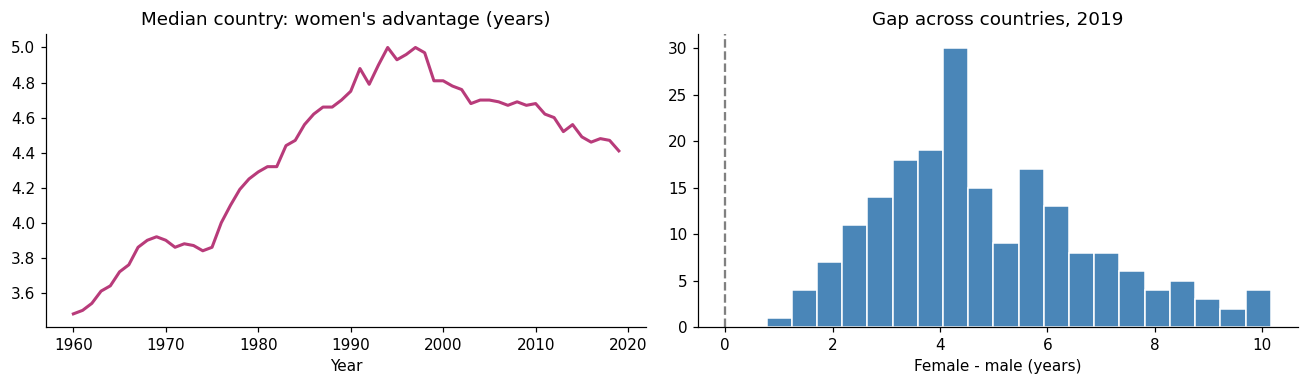

In [5]:
by_year = df.groupby("year")["gap"].agg(countries="count", median="median",
                                          share_women_longer=lambda s: (s > 0).mean(),
                                          min="min", max="max").round(2)
print(by_year.iloc[::6])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(by_year.index, by_year["median"], color="#b83b7a", lw=2)
ax[0].set_title("Median country: women's advantage (years)"); ax[0].set_xlabel("Year")
ax[1].hist(df[df.year == 2019]["gap"], bins=20, color="#4a86b8", edgecolor="white")
ax[1].axvline(0, color="grey", ls="--"); ax[1].set_title("Gap across countries, 2019"); ax[1].set_xlabel("Female - male (years)")
plt.tight_layout(); plt.show()

In [6]:
# Where did men outlive women, and where is the gap biggest?
print("Countries where men lived longer in at least one year:")
print(df[df.gap < 0].groupby("country")["year"].agg(["min", "max", "count"]).sort_values("count", ascending=False).head(10))
print()
print("Largest gaps ever recorded:")
print(df.sort_values("gap", ascending=False).head(6)[["country", "year", "gap"]].to_string(index=False))

Countries where men lived longer in at least one year:
                     min   max  count
country                              
Bangladesh          1960  1989     30
Maldives            1963  1991     29
India               1960  1978     19
Iraq                1960  1975     16
Iran, Islamic Rep.  1960  1975     12

Largest gaps ever recorded:
           country  year   gap
Iran, Islamic Rep.  1984 15.02
Iran, Islamic Rep.  1983 14.85
Iran, Islamic Rep.  1985 14.23
Russian Federation  1994 14.18
Iran, Islamic Rep.  1982 13.73
        Seychelles  1995 13.70


## 5. Choose the countries for the static graphic
The static graphic (Visual 5) compares **1960 vs 2019** for the **30 most populous countries** (by 2019 population). This keeps every row readable and labelled, and covers most of the world's people. The full table is still exported so the interactive version can scrub every year and every country.

In [7]:
START, END, N = 1960, 2019, 30

have_both = (df[df.year.isin([START, END])].groupby("code")["year"].nunique() == 2)
eligible = set(have_both[have_both].index)

top = (df[(df.year == END) & df.code.isin(eligible)]
         .sort_values("population", ascending=False).head(N)["code"])
df["featured"] = df["code"].isin(set(top))

feat = df[df.featured & df.year.isin([START, END])].pivot(index="country", columns="year", values="gap")
feat["change"] = (feat[END] - feat[START]).round(2)
feat = feat.sort_values(END, ascending=False)
feat

year,1960,2019,change
country,,,
Russian Federation,8.18,9.93,1.75
Philippines,4.24,8.24,4.00
Vietnam,7.05,8.22,1.17
Thailand,4.60,7.44,2.84
Brazil,3.81,7.31,3.50
South Africa,5.29,6.95,1.66
Myanmar,5.86,6.07,0.21
Japan,4.83,6.04,1.21
"Korea, Rep.",7.99,6.00,-1.99


In [8]:
print("Women outlive men in", int((feat[END] > 0).sum()), "of", len(feat), "countries in", END)
print("Men outlived women in", int((feat[START] < 0).sum()), "of", len(feat), "in", START, ":", list(feat.index[feat[START] < 0]))
print("Gap widened (> +0.5 yr):", int((feat["change"] > 0.5).sum()),
      "| narrowed (< -0.5):", int((feat["change"] < -0.5).sum()),
      "| about the same:", int((feat["change"].abs() <= 0.5).sum()))
print("Biggest widening:", feat["change"].idxmax(), feat["change"].max(), "| biggest narrowing:", feat["change"].idxmin(), feat["change"].min())

Women outlive men in 30 of 30 countries in 2019
Men outlived women in 3 of 30 in 1960 : ['Bangladesh', 'India', 'Iran, Islamic Rep.']
Gap widened (> +0.5 yr): 18 | narrowed (< -0.5): 6 | about the same: 6
Biggest widening: Bangladesh 5.17 | biggest narrowing: United Kingdom -2.3


## 6. Quick matplotlib sketch of the dumbbell (the D3 page is the real one)

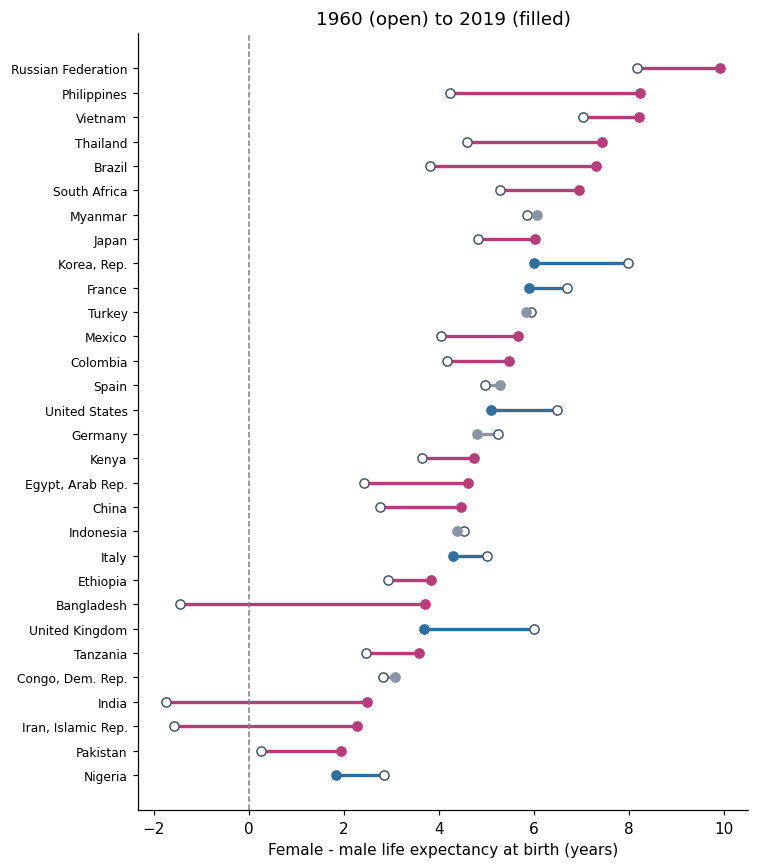

In [9]:
f = feat.sort_values(END)
fig, ax = plt.subplots(figsize=(7, 8))
for i, (name, r) in enumerate(f.iterrows()):
    col = "#b83b7a" if r["change"] > 0.5 else "#2f6f9f" if r["change"] < -0.5 else "#8a94a6"
    ax.plot([r[START], r[END]], [i, i], color=col, lw=2.2)
    ax.scatter(r[START], i, s=36, facecolor="white", edgecolor="#475569", zorder=3)
    ax.scatter(r[END], i, s=36, color=col, zorder=3)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(range(len(f))); ax.set_yticklabels(f.index, fontsize=8)
ax.set_xlabel("Female - male life expectancy at birth (years)")
ax.set_title(f"{START} (open) to {END} (filled)")
plt.tight_layout(); plt.show()

## 7. Export for the web page

In [10]:
out = (df[["country", "code", "year", "life_exp_female", "life_exp_male", "gap", "population", "featured"]]
         .sort_values(["code", "year"]))
out.to_csv("life_expectancy_gap.csv", index=False)
print(out.shape, "-> life_expectancy_gap.csv")
out.head()

(11730, 8) -> life_expectancy_gap.csv


,country,code,year,life_exp_female,life_exp_male,gap,population,featured
792,Aruba,ABW,1960,67.13,64.08,3.05,54208,False
4611,Aruba,ABW,1961,67.62,64.43,3.20,55434,False
9539,Aruba,ABW,1962,68.06,64.75,3.32,56234,False
5475,Aruba,ABW,1963,68.46,65.05,3.41,56699,False
628,Aruba,ABW,1964,68.82,65.36,3.46,57029,False
